# Figure 6 — E and I populations with different parameters

Pena, Vellmer, Bernardi, Roque & Lindner (2018), Front. Comput. Neurosci. 12:9, doi:10.3389/fncom.2018.00009. Scheme after Dummer, Wieland & Lindner (2014).

**Caption (paper):** Spectra of a network with two populations differing in their parameters vs the two-neuron scheme; τE = 20 ms, τI = 19 ms; (A) (gE, gI) = (4.2, 4.0), (B) (3.7, 3.7), (C) (4.25, 3.6). Reported rates: (A) νE = 3.2, νI = 9.7 Hz; (B) 128.9, 129.9 Hz; (C) 0.1, 7.4 Hz.

**Method here:** two-neuron scheme (Eqs. 12–13) vs a fixed in-degree network with N_E = 10,000 (paper 100,000), J = 0.1 mV, τD = 1.5 ms, RI_ext = 30 mV. Relative error: Eq. 19 with f_cut = 2 νI.

**Shared implementation choices** (all figures, see `pena_scheme.py`, `pena_network.py`):
- Euler, `dt = 0.1 ms`; voltage clamped at reset during the refractory period (scheme and network).
- Spectra: Eq. 5, two-sided, 2 s windows after a 1 s transient (Δf = 0.5 Hz).
  Fano factor = mean of S at 0.5 and 1 Hz divided by ν; τc from Eq. 7 with the estimator variance subtracted.
- Scheme generation 0: white noise at the diffusion-approximation (mean-field) rate; the paper does not
  specify its starting point. Inhibition-dominated cases (g > 4) use the all-past rate average (Eq. 11).
- Networks are simulated at reduced size (default N_E = 10,000 instead of 100,000) to fit 2 CPUs / ~2 GB;
  partners are drawn with replacement. Larger sizes are available via the config cell but need far more memory.

In [1]:
from pathlib import Path
import sys, json, time
import numpy as np
import matplotlib.pyplot as plt

HERE = Path.cwd()
if not (HERE / "pena2018_params.py").exists():
    HERE = HERE / "05_Pena2018_Replication"
sys.path.insert(0, str(HERE))

from pena2018_params import params_for
import pena_scheme as ps
import pena_runs as pr
FIGURES = HERE / "figures"; FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
P = params_for(6)
CASES = {"A": (4.2, 4.0), "B": (3.7, 3.7), "C": (4.25, 3.6)}
PAPER = P["reported_rates_Hz"] | {"A": (3.2, 9.7)}
N_E_NET, N_WINDOWS = 10_000, 10

In [3]:
runs = {}
for k, (gE, gI) in CASES.items():
    print(f"--- case {k}: gE={gE}, gI={gI}")
    runs[k] = (pr.two_pop(gE, gI, P), pr.two_pop(gE, gI, P, N_E=N_E_NET, n_windows=N_WINDOWS))

--- case A: gE=4.2, gI=4.0


gen  0:    5.93->   5.49 Hz    12.45->  11.85 Hz


gen  1:    5.49->   5.20 Hz    11.85->  12.53 Hz


gen  2:    5.20->   0.75 Hz    12.53->   4.61 Hz


gen  3:    2.98->  11.04 Hz     8.57->  17.83 Hz


gen  4:    5.67->   7.54 Hz    11.66->  15.95 Hz


... (74 outputs left out)

gen 37:    0.79->   0.27 Hz     8.05->   7.36 Hz


gen 38:    0.77->   0.27 Hz     8.03->   7.37 Hz


gen 39:    0.76->   0.26 Hz     8.02->   7.39 Hz


gen 40:    0.75->   0.26 Hz     8.00->   7.41 Hz
saved scheme_twopop_gE4.25_gI3.6_e52310edd9.npz (162 s)
loaded net_twopop_a3b4d6b25b.npz


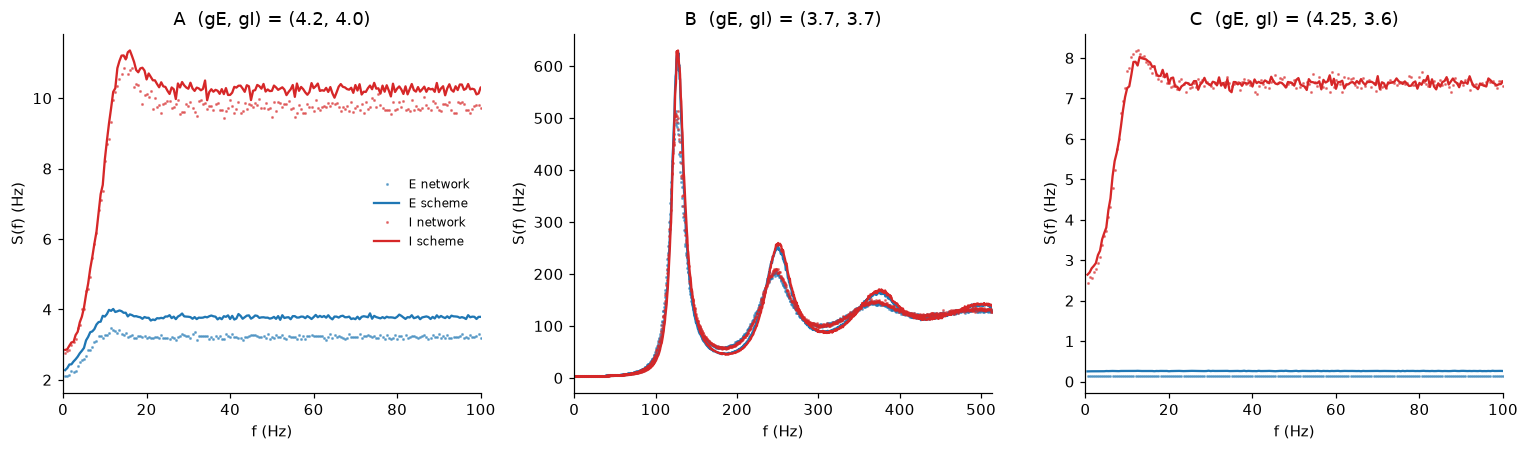

saved figure06_ei_heterogeneous.csv (24000 data points)


PosixPath('/workspaces/SC_Cortex/05_Pena2018_Replication/figures/figure06_ei_heterogeneous.csv')

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (k, (s, n)) in zip(axes, runs.items()):
    for a, (pop, c) in enumerate([("E", "tab:blue"), ("I", "tab:red")]):
        ax.plot(n["f"][1:], n[f"S_{pop}"][1:], ".", ms=2, color=c, alpha=0.5, label=f"{pop} network")
        ax.plot(s["f"][1:], s["S_final"][a][1:], "-", color=c, lw=1.5, label=f"{pop} scheme")
    nuI = float(n["nu_I"]); ax.set_xlim(0, max(4 * nuI, 100))
    ax.set(xlabel="f (Hz)", ylabel="S(f) (Hz)", title=f"{k}  (gE, gI) = {CASES[k]}")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES / "figure06_ei_heterogeneous.png", dpi=200); plt.show()
import pena_export; pena_export.figure_csv(fig, FIGURES / "figure06_ei_heterogeneous.csv")

In [5]:
print("case  nuE sch/net/paper        nuI sch/net/paper        rel.err E, I (Eq. 19)")
for k, (s, n) in runs.items():
    f = s["f"]; fcut = 2 * float(n["nu_I"])
    eE = ps.relative_error(f, n["S_E"], s["S_final"][0], fcut)
    eI = ps.relative_error(f, n["S_I"], s["S_final"][1], fcut)
    print(f"  {k}   {s['nu_final'][0]:6.2f}/{float(n['nu_E']):6.2f}/{PAPER[k][0]:6.1f}   "
          f"{s['nu_final'][1]:6.2f}/{float(n['nu_I']):6.2f}/{PAPER[k][1]:6.1f}   {eE:.3f}, {eI:.3f}")

case  nuE sch/net/paper        nuI sch/net/paper        rel.err E, I (Eq. 19)
  A     3.78/  3.20/   3.2    10.26/  9.77/   9.7   0.026, 0.002
  B   128.89/126.99/ 128.9   129.95/128.30/ 129.9   0.046, 0.042
  C     0.26/  0.14/   0.1     7.38/  7.38/   7.4   0.832, 0.001


## Notes

_Filled in after the run._